In [ ]:
#Build a Decision Tree Classifier using a dataset.
#Visualize a Decision Tree using plot_tree().
#Build a Random Forest Classifier and compare its accuracy with a Decision Tree.
#Create a Support Vector Machine (SVM) classifier for a classification dataset.
#Train a Gaussian Naive Bayes model and calculate its accuracy.

In [40]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt



In [57]:
data=load_breast_cancer()
df=pd.DataFrame(data.data, columns=data.feature_names)
df['target']=data.target
print(df.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [58]:
x=df.drop('target', axis=1)
y=df['target']

In [59]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [60]:
#model selection
model=DecisionTreeClassifier()
model.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [61]:
y_pred=model.predict(x_test)
y_pred

array([1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1,
       0, 1, 1, 0])

In [62]:
dt_accuracy=accuracy_score(y_test,y_pred)
print('Accuracy Score:',dt_accuracy)
print('Confusion Matrix:\n',confusion_matrix(y_test,y_pred))

Accuracy Score: 0.9473684210526315
Confusion Matrix:
 [[40  3]
 [ 3 68]]


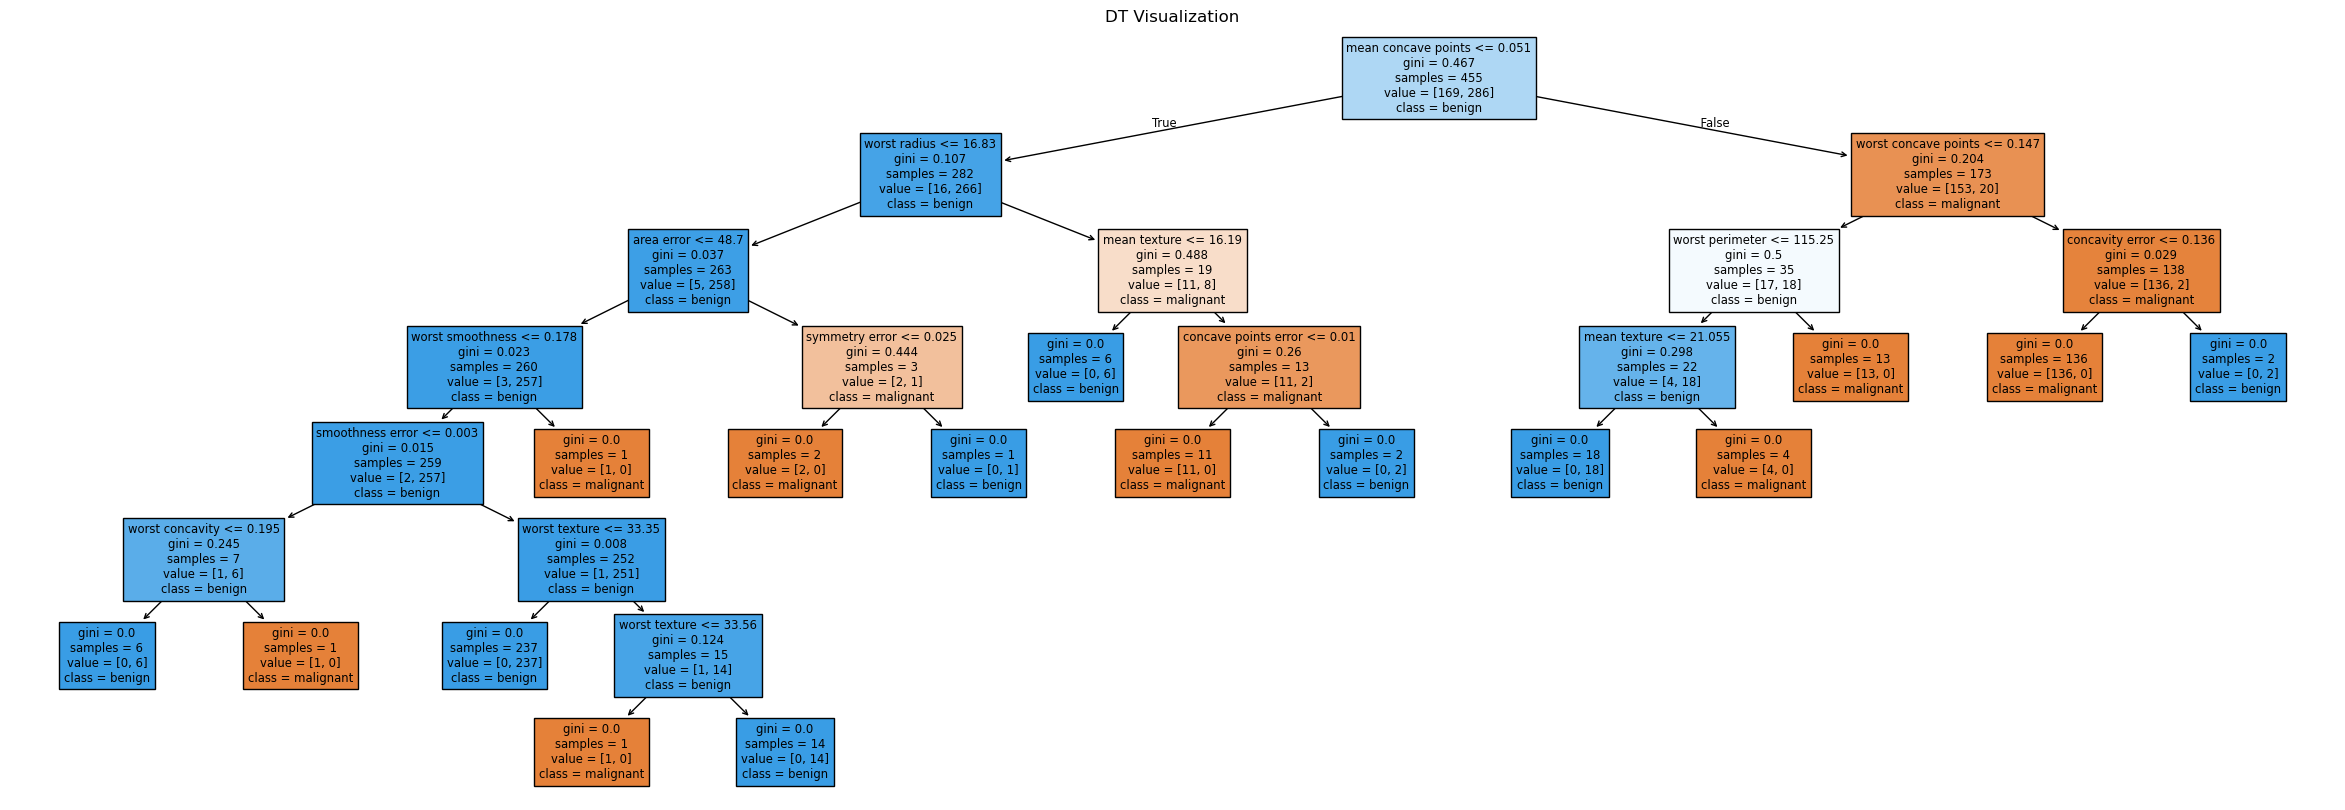

In [63]:
#Visualization
plt.figure(figsize=(30,10))
plot_tree(model,feature_names=data.feature_names,class_names=data.target_names,filled=True)
plt.title('DT Visualization')
plt.show()


In [64]:
#Build a Random Forest Classifier and compare its accuracy with a Decision Tree.

In [65]:
from sklearn.ensemble import RandomForestClassifier

In [66]:
rf_model=RandomForestClassifier(random_state=42)
rf_model.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [67]:
y_pred_rf=rf_model.predict(x_test)
y_pred_rf

array([1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 0])

In [68]:
rf_accuracy=accuracy_score(y_test,y_pred_rf)
print('Accuracy_score:',rf_accuracy)

Accuracy_score: 0.9649122807017544


In [69]:
#comparison
print('\nComparison')
print("DT Accuracy:",dt_accuracy)
print('Random Forest Accuracy',rf_accuracy)


Comparison
DT Accuracy: 0.9473684210526315
Random Forest Accuracy 0.9649122807017544


In [70]:
if rf_accuracy>dt_accuracy:
    print("Random Forest performed better")
elif rf_accuracy<dt_accuracy:
    print('DT performed better')
else:
    print('Both performed equally')

Random Forest performed better


In [71]:
#Create a Support Vector Machine (SVM) classifier for a classification dataset.

In [56]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

In [72]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [73]:
svm_model=SVC(kernel='rbf')
svm_model.fit(x_train,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [75]:
y_pred_svm=svm_model.predict(x_test)
y_pred_svm

array([1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 0])

In [76]:
svm_accuracy=accuracy_score(y_test,y_pred_svm)
print('SVM accuracy:',svm_accuracy)

SVM accuracy: 0.9473684210526315


In [78]:
print('Classification Report:\n',classification_report(y_test,y_pred_svm))

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.86      0.93        43
           1       0.92      1.00      0.96        71

    accuracy                           0.95       114
   macro avg       0.96      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



In [ ]:
#Train a Gaussian Naive Bayes model and calculate its accuracy.

In [79]:
from sklearn.naive_bayes import GaussianNB

In [80]:
nb_model=GaussianNB()
nb_model.fit(x_train,y_train)


,priors,None
,var_smoothing,1e-09


In [82]:
y_pred_nb=model.predict(x_test)
y_pred_nb

array([1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1,
       0, 1, 1, 0])

In [84]:
nb_accuracy=accuracy_score(y_test,y_pred_nb)
print('Gaussian Naive Bayes Accyracy:',nb_accuracy)

Gaussian Naive Bayes Accyracy: 0.9473684210526315


In [85]:
#Summary
print('\n----Accuracy Comaprison---')
print('DT Accuracy:',dt_accuracy)
print('Random Forest Accuracy:',rf_accuracy)
print('SVM Accuracy:',svm_accuracy)
print('Gaussian Naive Bayes Accyracy:',nb_accuracy)


----Accuracy Comaprison---
DT Accuracy: 0.9473684210526315
Random Forest Accuracy: 0.9649122807017544
SVM Accuracy: 0.9473684210526315
Gaussian Naive Bayes Accyracy: 0.9473684210526315
